# CV1   图像处理

## 本次作业主要分为以下四个步骤：
###     1. 制作kernel
###     2. 准备图片，存放在images文件夹，名为input
###     3. 实现padding（零填充和边缘复制）
###     4. 调用padding后进行filter

#### 注： 所有生成的图片都在results文件夹里

In [1]:
# 引入库函数
import sys
import cv2
import math
import pathlib
import numpy as np
from matplotlib import pyplot as plt

In [2]:
from pathlib import Path

project_dir = Path.home() / "projects" / "opencv-homework1"
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

### **Step1: 制作kernel**

#### 先实现一个根据所给的size和$\sigma$生成Gaussian Kernel的函数: myGaussianKernel(size, sigma)

In [3]:
def myGaussianKernel(size, sigma):
    kernel = np.zeros((size, size), dtype=np.float64)
    midX = size // 2
    midY = size // 2
    kernel[midY][midX] = 1
    for i in range(size):
        y = abs(i - midY)
        for j in range(size):
            x = abs(j - midX)
            kernel[i][j] = 1 / (math.exp((x**2 + y**2) / (2 * sigma**2)))
    kernel = kernel / np.sum(kernel)
    return kernel

#### 生成$size \in \{3, 5, 7\}, \sigma \in \{0.5, 1, 1.5\}$的九个高斯滤波核，并用matplotlib可视化

In [4]:
# 先生成字典kernels，存放九个滤波核，key是(size, sigma)
kernels = {}
sizes = [3, 5, 7]
sigmas = [0.5, 1.0, 1.5]

for size in sizes:
    for sigma in sigmas:
        kernels[(size, sigma)] = myGaussianKernel(size, sigma)

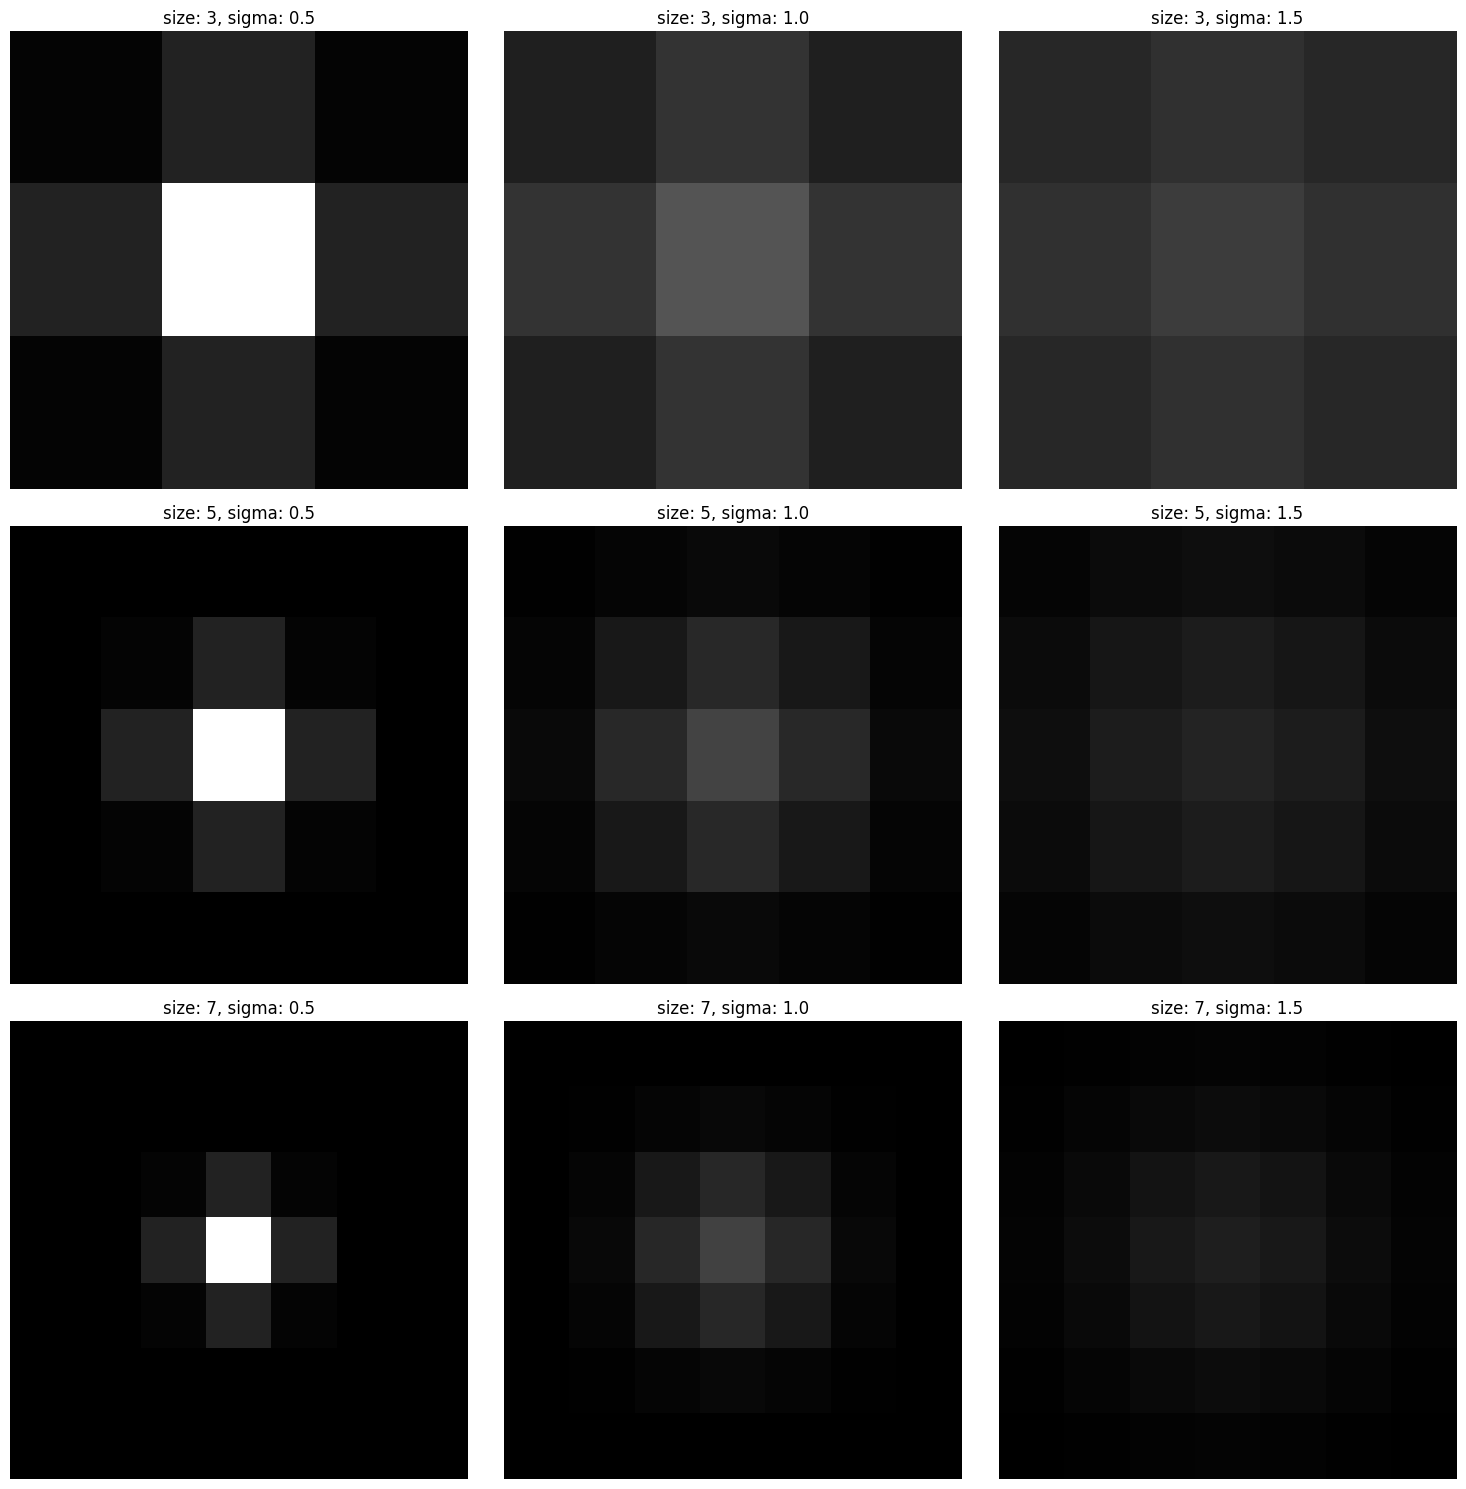

In [5]:
# 用matplotlib可视化
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

vmax = max([kernel.max() for kernel in kernels.values()]) #取最亮的那个点作为vmax

for row, size in enumerate(sizes):
    for col, sigma in enumerate(sigmas):
        kernel = kernels[(size, sigma)]
        axes[row][col].imshow(kernel, cmap='gray', vmin = 0, vmax = vmax)
        axes[row][col].axis("off")
        axes[row][col].set_title(f"size: {size}, sigma: {sigma}")
fig.tight_layout()

save_path = results_dir / "Gaussian_kernels.png"
fig.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

#### 用cv2生成高斯核，存到字典cvKernels中，将误差存到diffs中。
#### 输出每个kernel的最大误差

In [6]:
cvKernels = {}
diffs = {}
for size in sizes:
    for sigma in sigmas:
        g = cv2.getGaussianKernel(size, sigma)
        cvKernel = g @ g.T
        cvKernels[(size, sigma)] = cvKernel
        diff = kernels[(size, sigma)] - cvKernel
        diffs[(size, sigma)] = diff
        maxDiff = np.max(np.abs(diff))
        print(f"size: {size}, sigma: {sigma}, maxDiff: {maxDiff}")

size: 3, sigma: 0.5, maxDiff: 1.1102230246251565e-16
size: 3, sigma: 1.0, maxDiff: 5.551115123125783e-17
size: 3, sigma: 1.5, maxDiff: 2.7755575615628914e-17
size: 5, sigma: 0.5, maxDiff: 6.776263578034403e-21
size: 5, sigma: 1.0, maxDiff: 1.734723475976807e-18
size: 5, sigma: 1.5, maxDiff: 5.551115123125783e-17
size: 7, sigma: 0.5, maxDiff: 1.1102230246251565e-16
size: 7, sigma: 1.0, maxDiff: 2.7755575615628914e-17
size: 7, sigma: 1.5, maxDiff: 2.7755575615628914e-17


#### 相对误差热力图(红色代表我的值偏大，蓝色偏小，灰色则是几乎相同)

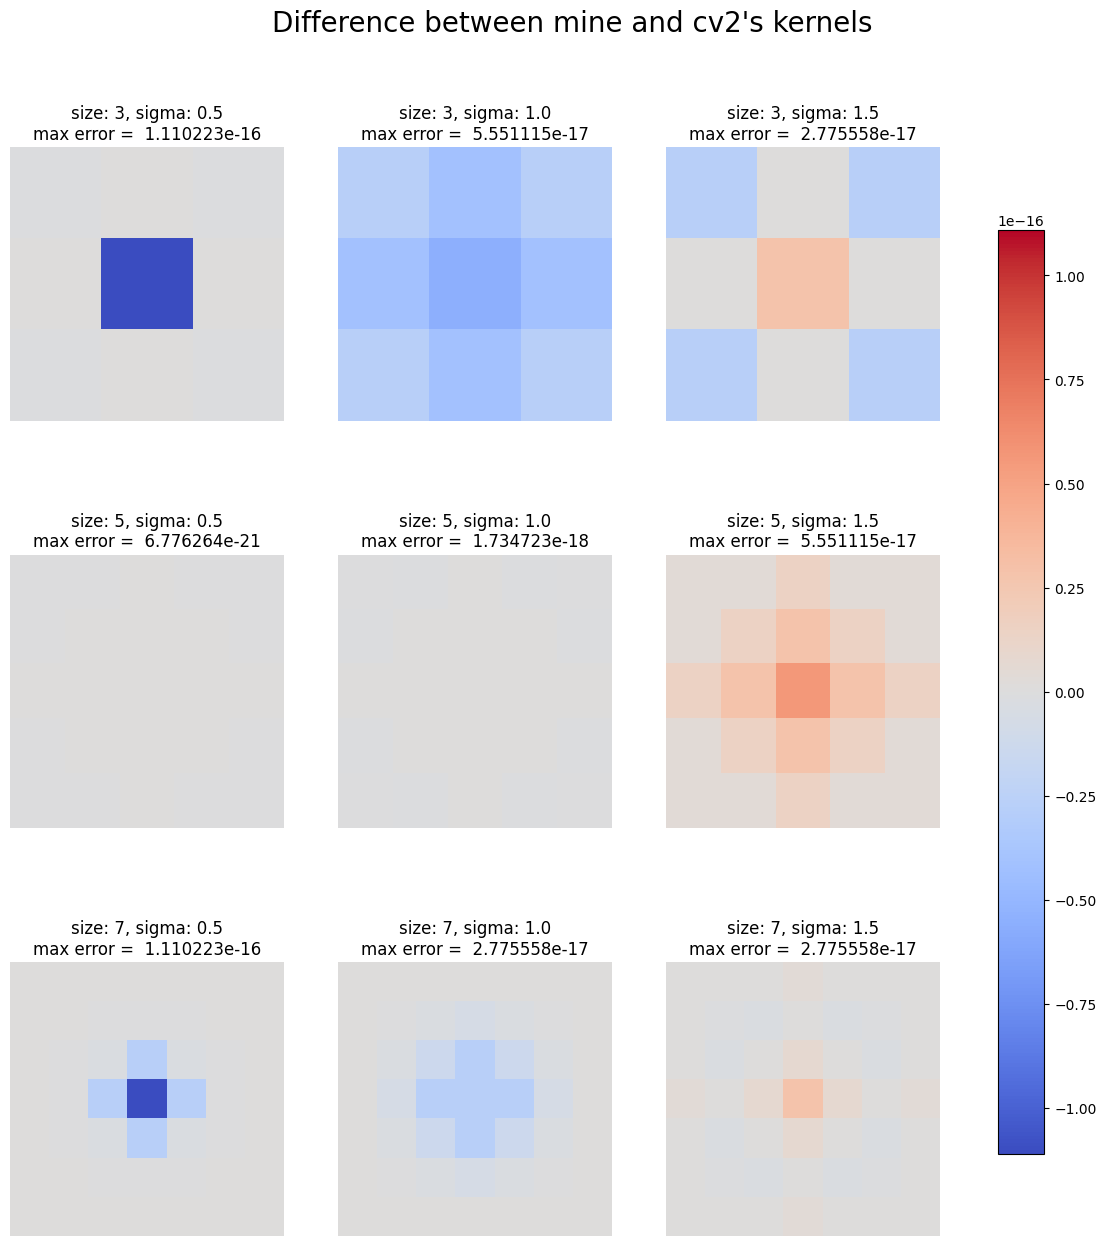

In [7]:
diffMax = max(np.max(np.abs(diff)) for diff in diffs.values())
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for row, size in enumerate(sizes):
    for col, sigma in enumerate(sigmas):
        diff = diffs[(size, sigma)]
        image = axes[row][col].imshow(diff, cmap='coolwarm', vmin = -diffMax, vmax = diffMax)
        axes[row][col].axis("off")
        axes[row][col].set_title(f"size: {size}, sigma: {sigma}\n"
                                 f"max error = {np.max(np.abs(diff)): 2e}")
fig.colorbar(image, ax = axes, shrink = 0.8)
fig.suptitle("Difference between mine and cv2's kernels", fontsize = 20, y = 0.95)
save_path = results_dir / "kernels_difference.png"
fig.savefig(save_path, dpi=200, bbox_inches='tight')
plt.show()

### **Step2: 准备图片(存入images, 黑白处理)**

#### 为了直观展示高斯核对像素强度的影响，本实验将图片转化为单通道灰度图进行处理（也可以减少工作量）

In [8]:
images_dir = project_dir / "images"
image_path = images_dir / "input.png"

image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
gray = image.astype(np.float64)

print(gray.shape)
print(gray.dtype)

(1499, 1080)
float64


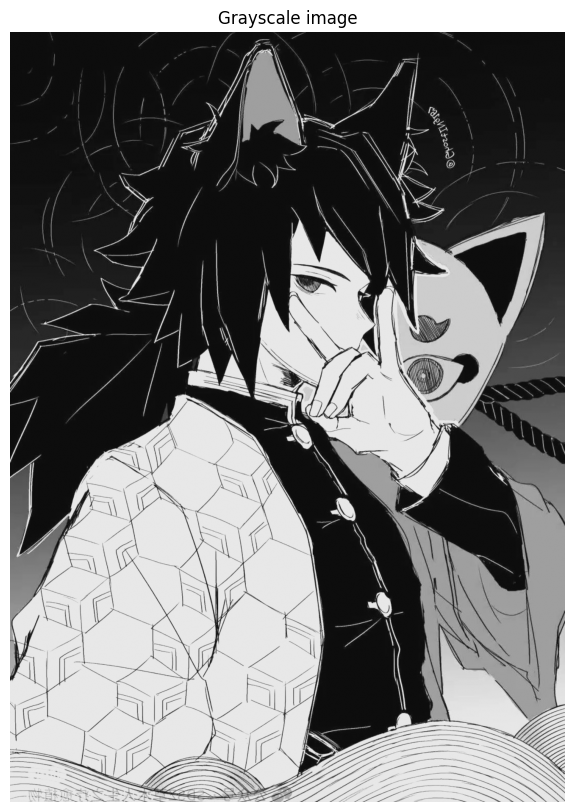

In [9]:
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(gray, cmap='gray', vmin = 0, vmax = 255)
ax.axis("off")
ax.set_title("Grayscale image")
plt.show()

### **Step3: 实现padding**

#### 先实现zeroPadding

In [10]:
def zeroPadding(gray, k): # k = size // 2
    m, n = gray.shape
    zeroPadded = np.zeros((m + 2*k, n + 2*k), dtype = np.float64)
    zeroPadded[k:(m + k), k:(n + k)] = gray
    return zeroPadded

In [11]:
zeroPadded = zeroPadding(gray, 2)
print("原图大小：", gray.shape)
print("填充后大小：", zeroPadded.shape)

原图大小： (1499, 1080)
填充后大小： (1503, 1084)


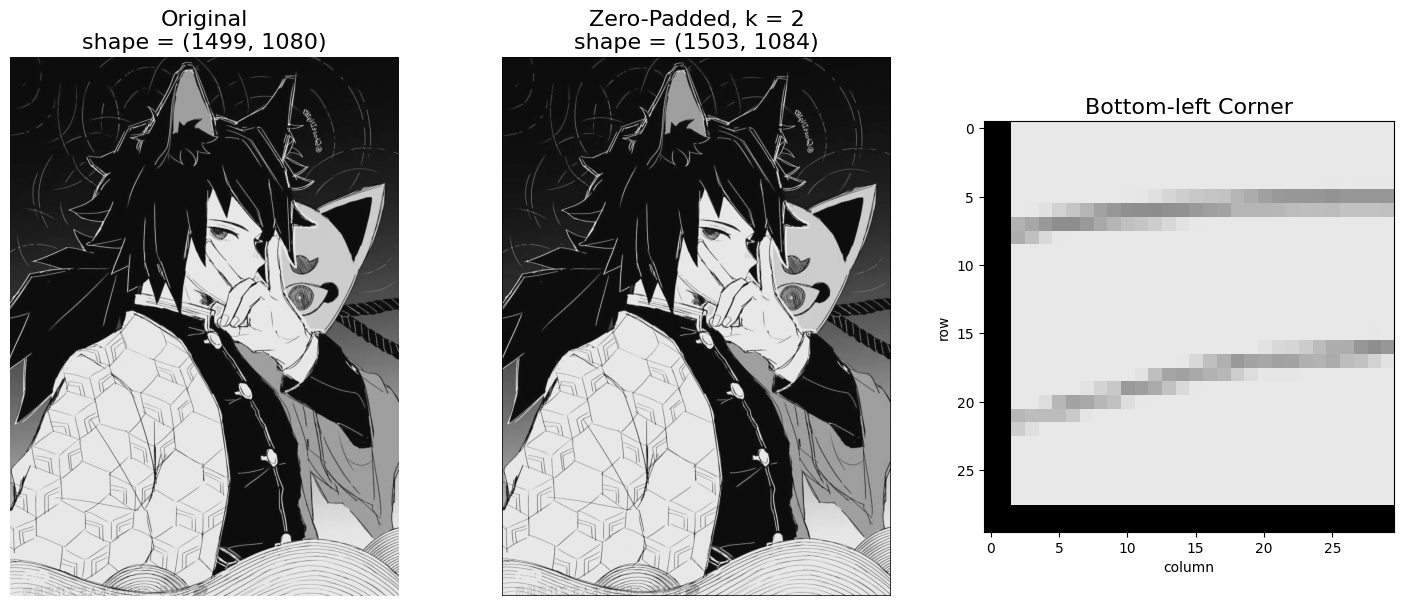

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
#原图
axes[0].imshow(gray, cmap='gray', vmin = 0, vmax = 255)
axes[0].set_title(f"Original\n"
                  f"shape = {gray.shape}", fontsize = 16)
axes[0].axis("off")

# 完整的零填充图
axes[1].imshow(zeroPadded, cmap='gray', vmin = 0, vmax = 255)
axes[1].set_title(f"Zero-Padded, k = 2\n"
                  f"shape = {zeroPadded.shape}", fontsize = 16)
axes[1].axis("off")

# 放大左下角
crop_size = 30
m, n = zeroPadded.shape
axes[2].imshow(zeroPadded[m - crop_size:m, :crop_size], cmap='gray', vmin = 0, vmax = 255, interpolation = "nearest")
axes[2].set_title("Bottom-left Corner", fontsize = 16)
axes[2].set_xlabel("column")
axes[2].set_ylabel("row")

fig.savefig(results_dir / "zero_padding.png", dpi=200, bbox_inches='tight')
plt.show()

#### 再实现边缘复制copyEdge

In [26]:
def copyEdge(gray, k): # k = size // 2
    m, n = gray.shape
    edgeCopied = np.zeros((m + 2*k, n + 2*k), dtype = np.float64)
    edgeCopied[k:(m + k), k:(n + k)] = gray

    # 先复制四个角
    for i in range(k):
        for j in range(k):
            edgeCopied[i][j] = gray[0][0]
            edgeCopied[i][n + k + j] = gray[0][n - 1]
            edgeCopied[m + k + i][j] = gray[m - 1][0]
            edgeCopied[m + k + i][n + k + j] = gray[m - 1][n - 1]

    # 再复制四条边
    for i in range(k):
        edgeCopied[k:(m + k) , i] = gray[:, 0]
        edgeCopied[k:(m + k), n + k + i] = gray[:, n - 1]
        edgeCopied[i, k:(n + k)] = gray[0, :]
        edgeCopied[m + k + i, k:(n + k)] = gray[m - 1, :]
    return edgeCopied

In [27]:
copyEdged = copyEdge(gray, 2)
print("原图大小：", gray.shape)
print("填充后大小：", copyEdged.shape)

原图大小： (1499, 1080)
填充后大小： (1503, 1084)


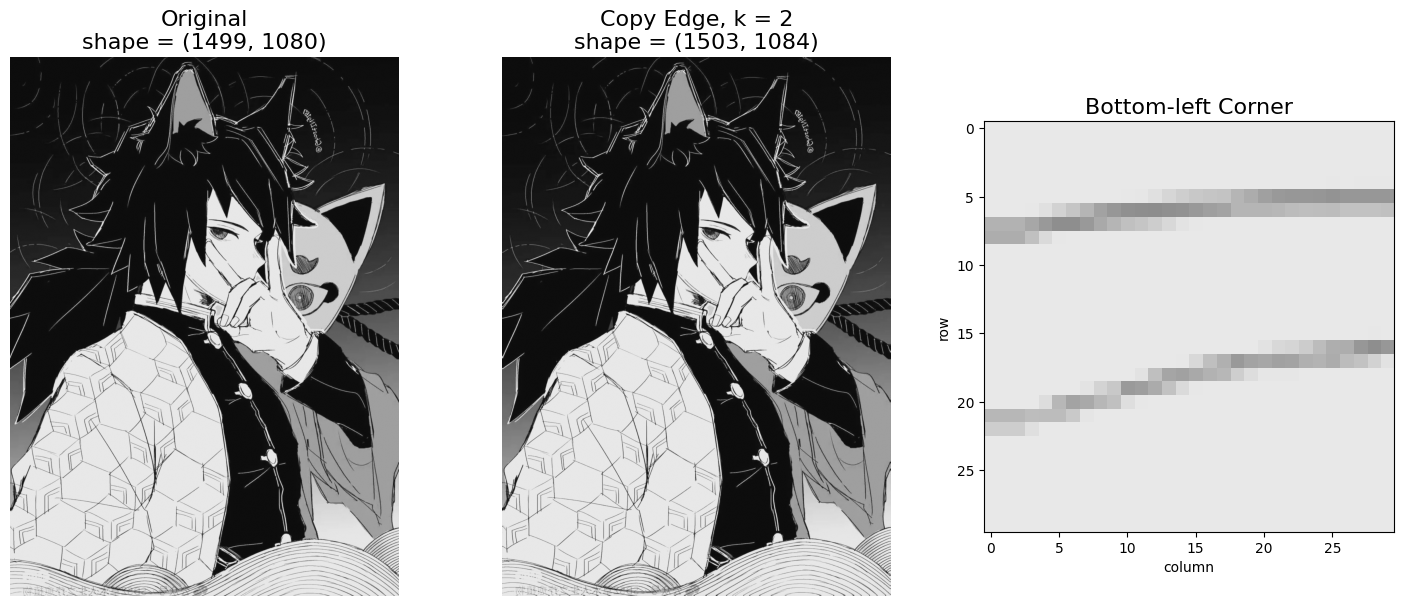

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
#原图
axes[0].imshow(gray, cmap='gray', vmin = 0, vmax = 255)
axes[0].set_title(f"Original\n"
                  f"shape = {gray.shape}", fontsize = 16)
axes[0].axis("off")

# 完整的零填充图
axes[1].imshow(copyEdged, cmap='gray', vmin = 0, vmax = 255)
axes[1].set_title(f"Copy Edge, k = 2\n"
                  f"shape = {copyEdged.shape}", fontsize = 16)
axes[1].axis("off")

# 放大左下角
crop_size = 30
m, n = copyEdged.shape
axes[2].imshow(copyEdged[m - crop_size:m, :crop_size], cmap='gray', vmin = 0, vmax = 255, interpolation = "nearest")
axes[2].set_title("Bottom-left Corner", fontsize = 16)
axes[2].set_xlabel("column")
axes[2].set_ylabel("row")

fig.savefig(results_dir / "copyEdge_padding.png", dpi=200, bbox_inches='tight')
plt.show()

### **Step4: 实现filter(调用copyEdge)**

In [31]:
def filter(gray, size, sigma):
    m, n = gray.shape
    kernel = myGaussianKernel(size, sigma)
    copyEdged = copyEdge(gray, size // 2)
    grayFilter = np.zeros((m, n), dtype = np.float64)
    for i in range(m):
        for j in range(n):
            patch = copyEdged[i:i + size, j:j + size]
            grayFilter[i][j] = np.sum(patch * kernel)
    return grayFilter

In [32]:
grayFilters = {}
for size in sizes:
    for sigma in sigmas:
        grayFilters[(size, sigma)] = filter(gray, size, sigma)

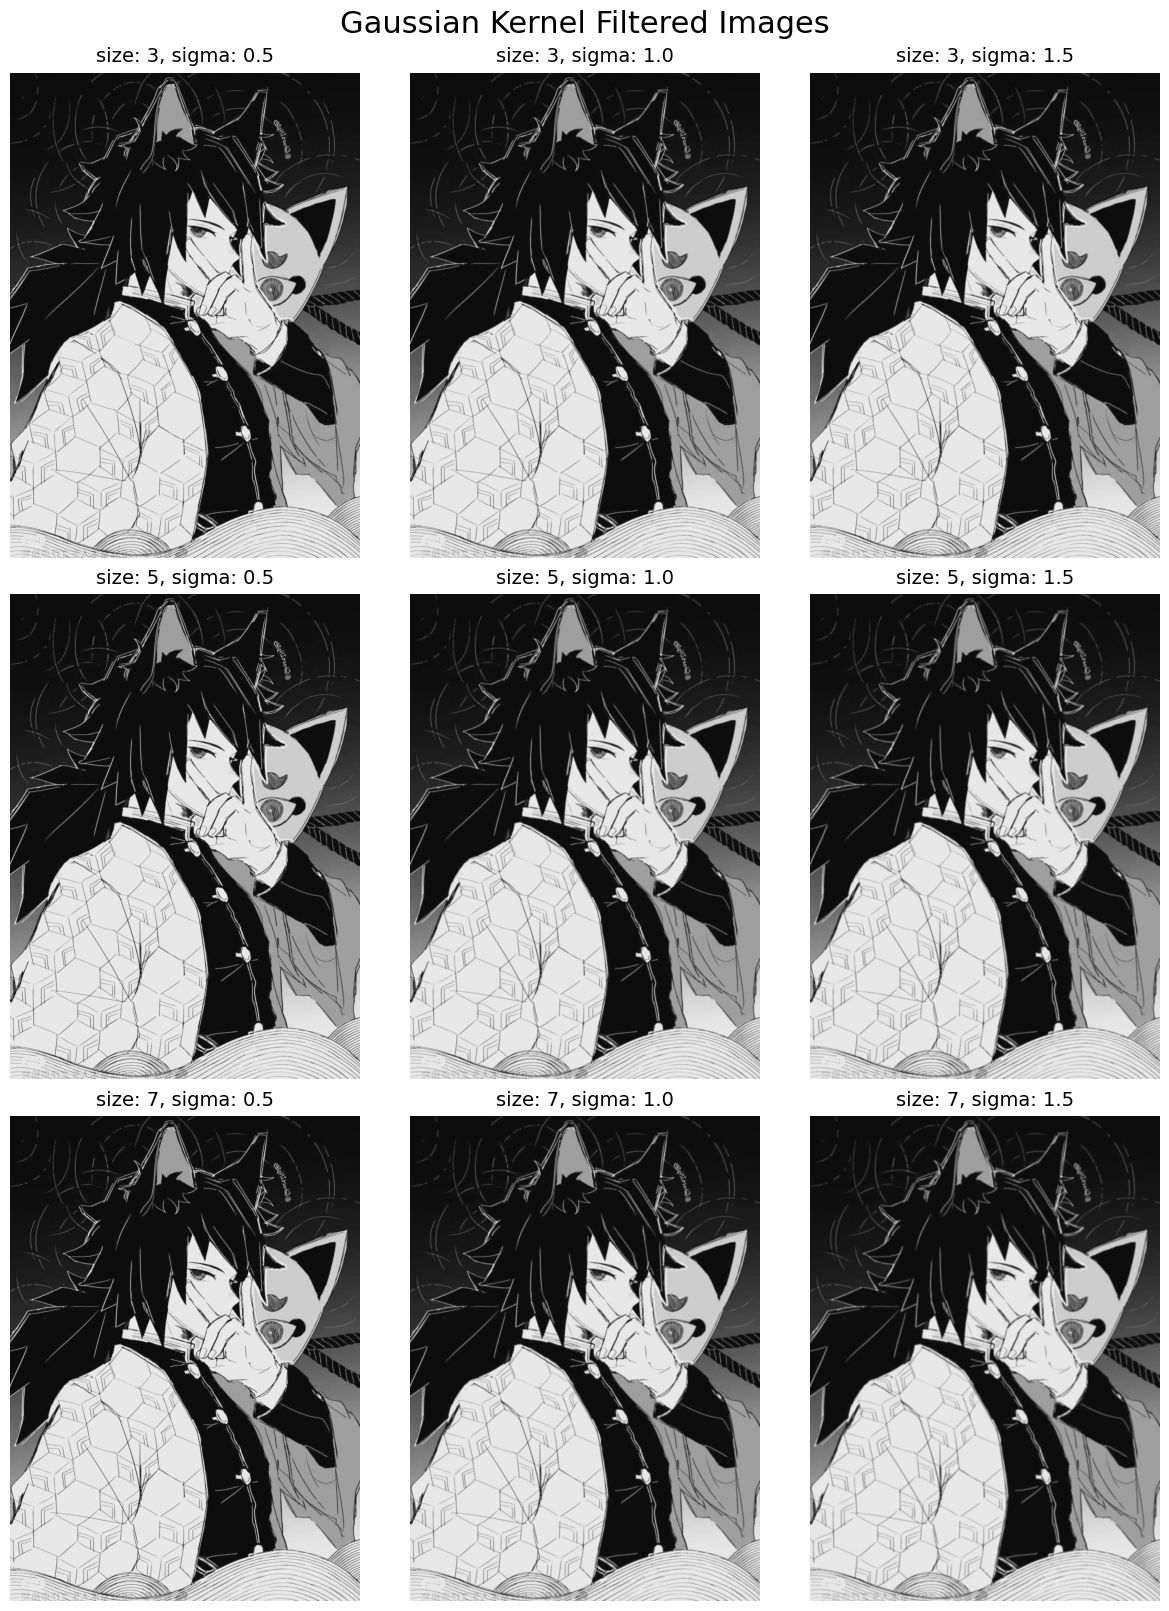

In [35]:
fig, axes = plt.subplots(3, 3, figsize=(12, 16), layout = "constrained")
for row, size in enumerate(sizes):
    for col, sigma in enumerate(sigmas):
        filteredImage = grayFilters[(size, sigma)]
        axes[row, col].imshow(filteredImage, cmap='gray', vmin = 0, vmax = 255)
        axes[row, col].axis("off")
        axes[row, col].set_title(f"size: {size}, sigma: {sigma}", fontsize = 14, pad = 8)
fig.suptitle("Gaussian Kernel Filtered Images", fontsize = 22)
save_path = results_dir / "gaussian_kernels_filtered.png"
fig.savefig(save_path, dpi=200, bbox_inches='tight')
plt.show()

#### 由于我选择的滤波核尺寸比较小，所以模糊的效果没有那么明显。但是仔细观察眼睛可以发现明显的模糊！